# Huấn luyện Random Forest

**Người thực hiện:** Lê Đỗ Hoà Thương

Huấn luyện và tinh chỉnh Random Forest bằng cross-validation
trên tập phát triển. Giữ riêng tập test để đánh giá cuối cùng.

Đầu vào gồm thông tin sinh viên và kết quả hai học kỳ đầu.

## 1.Thư viện

In [1]:
OWNER = "Lê Đỗ Hoà Thương"
OWNER_ID = "thuong"
MODEL_NAME = "Random Forest"
SCALE_NUMERIC = False

from pathlib import Path
from datetime import datetime
import hashlib, json, platform, uuid, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    GridSearchCV,
    cross_val_predict
)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    make_scorer,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Người thực hiện:", OWNER)
print("Mô hình:", MODEL_NAME)

Người thực hiện: Lê Đỗ Hoà Thương
Mô hình: Random Forest


## 2. Đọc và kiểm tra dữ liệu

In [2]:
project_dir = Path.cwd().resolve()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_path = project_dir / "data" / "processed" / "development.csv"

if not data_path.exists():
    raise FileNotFoundError(f"Không tìm thấy: {data_path}")

data = pd.read_csv(data_path)

# Làm sạch khoảng trắng trong tên cột
data.columns = [" ".join(c.split()) for c in data.columns]

assert not data.columns.duplicated().any(), "Tên cột bị trùng!"
assert data.isna().sum().sum() == 0, "Phát hiện dữ liệu thiếu!"

DATA_HASH = hashlib.sha256(data_path.read_bytes()).hexdigest()

print("Kích thước dữ liệu:", data.shape)
print("SHA256:", DATA_HASH)
display(data.head())

Kích thước dữ liệu: (3539, 37)
SHA256: dfe524288135ecf474ab9b9cf03277f19b818b879cafc176a571aa2a9dbaa690


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,43,1,9238,1,39,120.0,1,2,1,...,6,10,13,10,11.800000,0,13.9,-0.3,0.79,Graduate
1,1,39,1,9130,1,1,133.1,1,1,1,...,0,5,5,0,0.000000,5,12.7,3.7,-1.70,Dropout
2,1,44,1,9003,1,39,140.0,1,1,38,...,0,6,15,4,10.500000,0,15.5,2.8,-4.06,Enrolled
3,1,16,1,9070,1,1,125.0,1,1,1,...,0,6,6,6,12.833333,0,12.4,0.5,1.79,Graduate
4,1,17,1,9500,1,1,142.0,1,37,37,...,0,8,8,7,14.731429,0,10.8,1.4,1.74,Graduate


## 3. Tách đầu vào, mã hoá nhãn và thiết lập CV

In [3]:
X = data.drop(columns="Target")

label_names = ["Dropout", "Enrolled", "Graduate"]
label_mapping = {
    label: i for i, label in enumerate(label_names)
}

assert set(data["Target"].unique()) == set(label_names)

y = data["Target"].map(label_mapping).astype(int)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(cv.split(X, y))

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
    "recall_dropout": make_scorer(
        recall_score,
        labels=[0],
        average="macro",
        zero_division=0
    )
}

print("X:", X.shape, "| y:", y.shape)
print("Mã nhãn:", label_mapping)
print("Số fold:", len(folds))

X: (3539, 36) | y: (3539,)
Mã nhãn: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
Số fold: 5


## 4. Tạo thư mục lưu kết quả

In [4]:
experiment_dir = project_dir / "experiments" / OWNER_ID
figure_dir = project_dir / "report" / "figures" / OWNER_ID
model_dir = project_dir / "models" / OWNER_ID

for directory in [experiment_dir, figure_dir, model_dir]:
    directory.mkdir(parents=True, exist_ok=True)

print("Thư mục Excel:", experiment_dir)
print("Thư mục biểu đồ:", figure_dir)
print("Thư mục mô hình:", model_dir)
print("Chưa đọc test.csv và chưa huấn luyện mô hình.")

Thư mục Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\thuong
Thư mục biểu đồ: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\report\figures\thuong
Thư mục mô hình: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\models\thuong
Chưa đọc test.csv và chưa huấn luyện mô hình.


## 5. Xây dựng tiền xử lý

In [5]:
categorical_cols = ['Marital status', 'Application mode', 'Course', 'Previous qualification',
    'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
binary_cols = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
numeric_cols = ['Application order', 'Previous qualification (grade)', 'Admission grade',
    'Age at enrollment', 'Unemployment rate', 'Inflation rate', 'GDP'] + [
    f'Curricular units {semester} sem ({measure})'
    for semester in ['1st', '2nd'] for measure in [
        'credited', 'enrolled', 'evaluations', 'approved', 'grade', 'without evaluations']]
assigned = categorical_cols + binary_cols + numeric_cols
assert len(assigned) == len(set(assigned)) == 36
assert set(assigned) == set(X.columns)
for col in binary_cols:
    assert set(X[col].unique()) <= {0, 1}, col

def build_pipeline(estimator):
    processor = ColumnTransformer([
        ('category', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('numeric', StandardScaler() if SCALE_NUMERIC else 'passthrough', numeric_cols),
        ('binary', 'passthrough', binary_cols)
    ])
    return Pipeline([('preprocessing', processor), ('model', estimator)])

print('Đủ 36 đặc trưng. Pipeline sẽ fit tiền xử lý riêng trong từng fold.')


Đủ 36 đặc trưng. Pipeline sẽ fit tiền xử lý riêng trong từng fold.


## 6. Nhật ký Excel

In [7]:
log_path = experiment_dir / 'experiment_history.xlsx'

def save_log(row):
    # Đóng Excel trước khi chạy để tránh PermissionError trên Windows.
    frame = pd.DataFrame([row])
    if log_path.exists():
        old = pd.read_excel(log_path, sheet_name='Runs')
        frame = pd.concat([old, frame], ignore_index=True)
    frame.to_excel(log_path, sheet_name='Runs', index=False, engine='openpyxl')
    print('Đã ghi Excel:', log_path)

## 7. Hàm đánh giá mô hình bằng cross-validation

In [6]:
results = []
def run_cv(estimator, name, note):
    run_id = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:6]
    scores = cross_validate(estimator, X, y, cv=folds, scoring=scoring,
        return_train_score=True, n_jobs=1, error_score='raise')
    details = pd.DataFrame({k: v for k, v in scores.items()})
    details.insert(0, 'fold', range(1, 6))
    details.to_csv(experiment_dir / f'{run_id}_folds.csv', index=False)
    row = {
        'Run_ID': run_id, 'Timestamp': datetime.now().isoformat(timespec='seconds'),
        'Run_By': OWNER, 'Model': name, 'Stage': 'CV fixed configuration',
        'Data_SHA256': DATA_HASH, 'Samples': len(y),
        'Split': 'development 80%; StratifiedKFold 5; shuffle=True; seed=42',
        'Parameters': json.dumps(estimator.get_params(deep=False), default=str, ensure_ascii=False),
        'Preprocessing': 'OneHot categorical; binary passthrough; numeric ' + ('StandardScaler' if SCALE_NUMERIC else 'passthrough'),
        'Train_Macro_F1': scores['train_macro_f1'].mean(),
        'CV_Macro_F1': scores['test_macro_f1'].mean(),
        'CV_Macro_F1_STD': scores['test_macro_f1'].std(ddof=1),
        'CV_Accuracy': scores['test_accuracy'].mean(),
        'CV_Weighted_F1': scores['test_weighted_f1'].mean(),
        'CV_Recall_Dropout': scores['test_recall_dropout'].mean(),
        'Mean_Fit_Seconds': scores['fit_time'].mean(),
        'Python': platform.python_version(), 'sklearn': sklearn.__version__,
        'Note': note
    }
    save_log(row)
    results.append(row)
    display(pd.DataFrame([row])[['Model', 'Train_Macro_F1', 'CV_Macro_F1', 'CV_Macro_F1_STD', 'CV_Accuracy', 'CV_Recall_Dropout']])
    return scores

## 8. Baseline Dummy

In [9]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
dummy_scores = run_cv(DummyClassifier(strategy='most_frequent'), 'Dummy most frequent', 'Baseline; ignores input features.')

Đã ghi Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\thuong\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,Dummy most frequent,0.222013,0.222013,0.000209,0.499294,0.0


## 9. Mô hình ban đầu

In [11]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=1)
param_grid = {"model__max_depth": [8, None], "model__min_samples_leaf": [1, 5], "model__class_weight": [None, "balanced"]}
initial_scores = run_cv(build_pipeline(model), MODEL_NAME + ' initial', 'Fixed initial configuration before tuning.')

Đã ghi Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\thuong\experiment_history.xlsx


,Model,Train_Macro_F1,CV_Macro_F1,CV_Macro_F1_STD,CV_Accuracy,CV_Recall_Dropout
0,Random Forest initial,1.0,0.676577,0.033784,0.772537,0.773939


### Nhận xét mô hình ban đầu

- Random Forest đạt CV Macro-F1 = 0,6766, cao hơn Dummy
  (0,2220), cho thấy mô hình khai thác được thông tin từ đặc trưng.
- CV Accuracy đạt 77,25%, so với 49,93% của Dummy.
- Recall Dropout trung bình qua 5 fold đạt 77,39%;
  Dummy không phát hiện được mẫu Dropout nào.
- Train Macro-F1 đạt 1,0000 nhưng CV Macro-F1 chỉ đạt 0,6766.
  Khoảng cách lớn cho thấy dấu hiệu overfitting.
- Độ lệch chuẩn CV Macro-F1 là 0,0338, cho thấy kết quả
  có dao động giữa các fold.
- Tiếp theo, thử giới hạn độ sâu cây, tăng số mẫu tối thiểu
  tại lá và điều chỉnh trọng số lớp để kiểm tra khả năng cải thiện.
- Đây là kết quả cross-validation trên tập phát triển,
  chưa phải kết quả trên tập test.

## 10. Tinh chỉnh siêu tham số

### 10.1 Chạy tunning

In [12]:
search = GridSearchCV(
    build_pipeline(model),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=folds,
    refit=True,
    n_jobs=1,
    return_train_score=True,
    error_score="raise"
)

started = time.perf_counter()
search.fit(X, y)
elapsed = time.perf_counter() - started

print("Hoàn thành tuning:", round(elapsed, 2), "giây")

Hoàn thành tuning: 85.01 giây


### 10.2 Lưu kết quả CSV và Excel

In [13]:
search_id = (
    datetime.now().strftime("%Y%m%d_%H%M%S")
    + "_" + uuid.uuid4().hex[:6]
)

search_table = pd.DataFrame(search.cv_results_)
search_table.to_csv(
    experiment_dir / f"{search_id}_grid_search.csv",
    index=False
)

existing = (
    pd.read_excel(log_path, sheet_name="Runs")
    if log_path.exists()
    else pd.DataFrame()
)

tuning_rows = []

for i, params in enumerate(search.cv_results_["params"]):
    tuning_rows.append({
        "Run_ID": f"{search_id}_candidate_{i + 1}",
        "Timestamp": datetime.now().isoformat(timespec="seconds"),
        "Run_By": OWNER,
        "Model": MODEL_NAME,
        "Stage": "GridSearchCV candidate",
        "Data_SHA256": DATA_HASH,
        "Samples": len(y),
        "Split": "Same development; same 5 folds; seed=42",
        "Parameters": json.dumps(params, ensure_ascii=False),
        "Preprocessing": (
            "OneHot; binary passthrough; numeric "
            + ("StandardScaler" if SCALE_NUMERIC else "passthrough")
        ),
        "Train_Macro_F1": search.cv_results_["mean_train_score"][i],
        "CV_Macro_F1": search.cv_results_["mean_test_score"][i],
        "CV_Macro_F1_STD": search.cv_results_["std_test_score"][i],
        "Mean_Fit_Seconds": search.cv_results_["mean_fit_time"][i],
        "Python": platform.python_version(),
        "sklearn": sklearn.__version__,
        "Note": "Điểm dùng chọn tham số; chưa đánh giá test độc lập."
    })

pd.concat(
    [existing, pd.DataFrame(tuning_rows)],
    ignore_index=True
).to_excel(
    log_path,
    sheet_name="Runs",
    index=False,
    engine="openpyxl"
)

print("Đã lưu mọi cấu hình vào Excel:", log_path)

Đã lưu mọi cấu hình vào Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\thuong\experiment_history.xlsx


### 10.3 Hiển thi kết quả

In [18]:
print("Tham số tốt nhất:", search.best_params_)
print("CV Macro-F1 tốt nhất:", round(search.best_score_, 4))
print("Số cấu hình:", len(tuning_rows))
print("Thời gian:", round(elapsed, 2), "giây")

display(
    search_table[[
        "params",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]].sort_values("rank_test_score")
)

print("Kết quả cross-validation trên tập phát triển; chưa đánh giá tập test.")

Tham số tốt nhất: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 1}
CV Macro-F1 tốt nhất: 0.7162
Số cấu hình: 8
Thời gian: 85.01 giây


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
6,"{'model__class_weight': 'balanced', 'model__ma...",0.999940,0.716244,0.018026,1
7,"{'model__class_weight': 'balanced', 'model__ma...",0.830010,0.708224,0.025489,2
4,"{'model__class_weight': 'balanced', 'model__ma...",0.789818,0.699353,0.023284,3
5,"{'model__class_weight': 'balanced', 'model__ma...",0.755367,0.697898,0.021213,4
2,"{'model__class_weight': None, 'model__max_dept...",1.000000,0.676577,0.030218,5
3,"{'model__class_weight': None, 'model__max_dept...",0.781920,0.632026,0.028777,6
0,"{'model__class_weight': None, 'model__max_dept...",0.712761,0.590464,0.018395,7
1,"{'model__class_weight': None, 'model__max_dept...",0.650017,0.584599,0.019257,8


Kết quả cross-validation trên tập phát triển; chưa đánh giá tập test.


### Nhận xét kết quả tinh chỉnh

- Đã thử 8 cấu hình bằng Stratified 5-fold CV.
- Cấu hình tốt nhất đạt CV Macro-F1 = 0,7162,
  tăng 0,0397 so với cấu hình ban đầu (0,6766).
- Cả bốn cấu hình dùng class_weight="balanced" đều đạt
  điểm CV cao hơn các cấu hình không dùng trọng số lớp.
- Cấu hình hạng 1 có Train Macro-F1 = 0,9999,
  cho thấy khoảng cách train/validation vẫn lớn.
- Cấu hình hạng 2 đạt CV Macro-F1 = 0,7082 và
  Train Macro-F1 = 0,8300, có khoảng cách nhỏ hơn.
- Chưa đủ căn cứ khẳng định chênh lệch giữa hai cấu hình
  đứng đầu là đáng kể.
- Điểm trên là kết quả dùng lựa chọn tham số bằng CV,
  chưa phải đánh giá độc lập trên tập test.

In [17]:
for name, value in search.best_params_.items():
    print(name, "=", value)

model__class_weight = balanced
model__max_depth = None
model__min_samples_leaf = 1


## 11. Phân tích lỗi và so sánh baseline

,precision,recall,f1-score,support
Dropout,0.8111,0.7740,0.7921,1137.0000
Enrolled,0.6074,0.2850,0.3880,635.0000
Graduate,0.7760,0.9468,0.8529,1767.0000
accuracy,0.7725,0.7725,0.7725,0.7725
macro avg,0.7315,0.6686,0.6777,3539.0000
weighted avg,0.7570,0.7725,0.7500,3539.0000


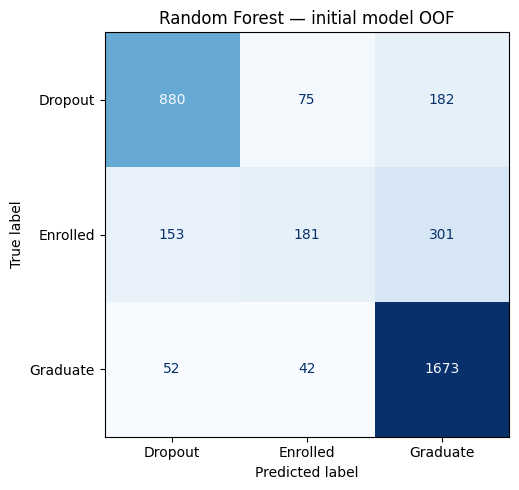

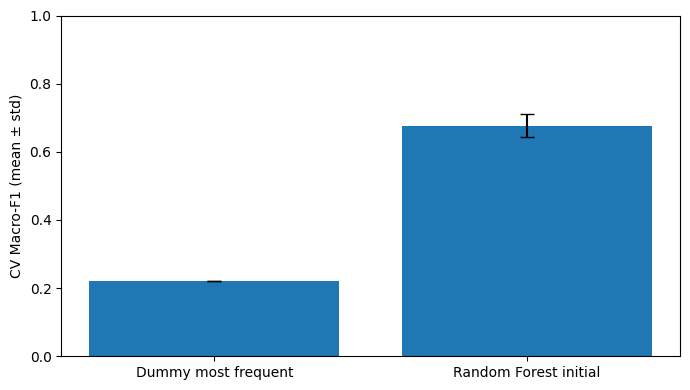

In [15]:
# OOF cho cấu hình ban đầu, chưa được chọn bằng tuning.
# Mỗi mẫu được dự đoán bởi mô hình không fit trên mẫu đó.
oof_pred = cross_val_predict(build_pipeline(model), X, y, cv=folds, n_jobs=1)
labels = [0, 1, 2]
report = classification_report(y, oof_pred, labels=labels, target_names=label_names, output_dict=True, zero_division=0)
display(pd.DataFrame(report).T.round(4))
pd.DataFrame(report).T.to_csv(experiment_dir / 'initial_model_oof_report.csv', encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y, oof_pred, labels=labels, display_labels=label_names, ax=ax, cmap='Blues', colorbar=False)
ax.set_title(MODEL_NAME + ' — initial model OOF')
fig.tight_layout()
fig.savefig(figure_dir / 'initial_model_oof_confusion.png', dpi=200)
plt.show()
plt.close(fig)

comparison = pd.DataFrame(results).set_index('Model')
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(comparison.index, comparison['CV_Macro_F1'], yerr=comparison['CV_Macro_F1_STD'], capsize=5)
ax.set_ylim(0, 1)
ax.set_ylabel('CV Macro-F1 (mean ± std)')
fig.tight_layout()
fig.savefig(figure_dir / 'baseline_comparison.png', dpi=200)
plt.show()
plt.close(fig)


### Nhận xét phân tích lỗi

- Trên dự đoán OOF, Random Forest ban đầu đạt Accuracy 77,25%
  và Macro-F1 0,6777.
- Graduate được nhận diện tốt nhất: Recall 94,68%, F1-score 0,8529;
  dự đoán đúng 1.673/1.767 mẫu.
- Dropout đạt Recall 77,40%, F1-score 0,7921;
  dự đoán đúng 880/1.137 mẫu. Có 182 mẫu bị nhầm thành Graduate
  và 75 mẫu bị nhầm thành Enrolled.
- Enrolled khó nhận diện nhất: Recall 28,50%, F1-score 0,3880.
  Chỉ 181/635 mẫu được dự đoán đúng; 301 mẫu bị nhầm thành
  Graduate và 153 mẫu bị nhầm thành Dropout.
- Kết quả cho thấy Accuracy tổng thể chưa phản ánh đầy đủ
  hạn chế ở lớp Enrolled, vì vậy cần theo dõi Macro-F1
  và metric riêng từng lớp.
- Biểu đồ CV cho thấy Random Forest tốt hơn Dummy rõ rệt:
  Macro-F1 trung bình 0,6766 so với 0,2220.
- Đây là phân tích mô hình ban đầu, chưa phải mô hình sau tuning
  hoặc kết quả đánh giá trên tập test.

## 12. Lưu pipeline ứng viên

In [16]:
import joblib
# GridSearchCV đã refit cấu hình tốt nhất trên toàn bộ development.
# Đây là mô hình ứng viên; chưa xác nhận chất lượng trên test.
model_path = model_dir / 'candidate_pipeline.joblib'
joblib.dump(search.best_estimator_, model_path)
metadata = {
    'owner': OWNER, 'model': MODEL_NAME, 'data_sha256': DATA_HASH,
    'best_params': search.best_params_, 'selection_cv_macro_f1': search.best_score_,
    'test_evaluated': False, 'sklearn': sklearn.__version__,
    'label_mapping': label_mapping, 'feature_columns': X.columns.tolist()
}
(model_dir / 'metadata.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu pipeline ứng viên:', model_path)
print('Nhật ký Excel:', log_path)
print('Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.')


Đã lưu pipeline ứng viên: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\models\thuong\candidate_pipeline.joblib
Nhật ký Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\thuong\experiment_history.xlsx
Chưa đánh giá test. Nhóm chọn mô hình bằng CV trước.


## Nhật ký tiến độ cá nhân

| Ngày | Công việc | Kết quả | Khó khăn | Bước tiếp theo |
|---|---|---|---|---|
| 31/10/2026 | Chạy Dummy và Random Forest ban đầu | CV Macro-F1 lần lượt là 0,2220 và 0,6766 | Thiếu openpyxl khi ghi Excel; đã cài bổ sung | Tinh chỉnh siêu tham số |
| 31/10/2026 | Phân tích lỗi mô hình ban đầu bằng OOF | Enrolled có Recall thấp nhất: 28,50% | Mô hình còn nhầm nhiều Enrolled thành Graduate | Tổng hợp kết quả tuning |